# Superstore Sales Analysis

**Tech Stack:** Python, Pandas, Matplotlib

This notebook performs data loading, quality checks, KPI analysis, regional/category analysis, discount-profitability analysis, return-rate analysis and trend exploration.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

orders = pd.read_csv('../data/orders.csv', parse_dates=['Order Date','Ship Date'])
returns = pd.read_csv('../data/returns.csv')
people = pd.read_csv('../data/people.csv')
orders.shape, returns.shape, people.shape

((9994, 21), (296, 2), (4, 2))

In [2]:
orders.info()
orders.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## Data Quality

In [3]:
quality = pd.DataFrame({
    'Missing Values': orders.isna().sum(),
    'Unique Values': orders.nunique()
})
quality[quality['Missing Values'] > 0]

,Missing Values,Unique Values


## KPI Summary

In [4]:
kpis = {
    'Total Sales': orders['Sales'].sum(),
    'Total Profit': orders['Profit'].sum(),
    'Profit Margin %': orders['Profit'].sum()/orders['Sales'].sum()*100,
    'Total Quantity': orders['Quantity'].sum(),
    'Unique Orders': orders['Order ID'].nunique(),
    'Unique Customers': orders['Customer ID'].nunique(),
}
pd.Series(kpis).round(2)

Total Sales         2297200.86
Total Profit         286397.02
Profit Margin %          12.47
Total Quantity        37873.00
Unique Orders          5009.00
Unique Customers        793.00
dtype: float64

## Regional Performance

In [5]:
region = orders.groupby('Region', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Quantity=('Quantity','sum'), Orders=('Order ID','nunique'))
region['Margin %'] = region['Profit']/region['Sales']*100
region.sort_values('Sales', ascending=False).round(2)

,Region,Sales,Profit,Quantity,Orders,Margin %
3,West,725457.82,108418.45,12266,1611,14.94
1,East,678781.24,91522.78,10618,1401,13.48
0,Central,501239.89,39706.36,8780,1175,7.92
2,South,391721.90,46749.43,6209,822,11.93


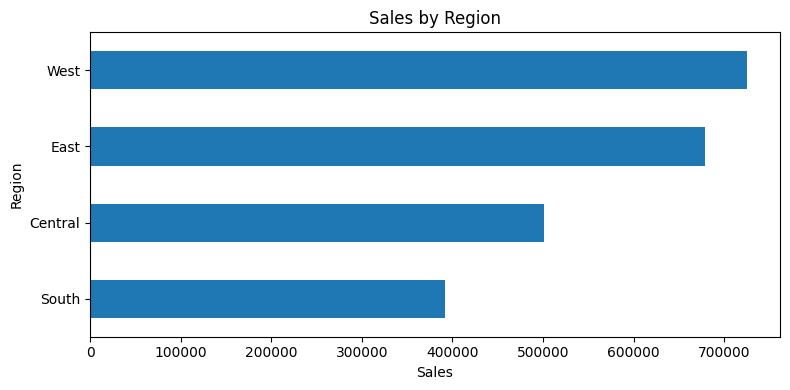

In [6]:
ax=region.sort_values('Sales').plot(kind='barh', x='Region', y='Sales', legend=False, figsize=(8,4), title='Sales by Region')
ax.set_xlabel('Sales')
plt.tight_layout()
plt.show()

## Category & Sub-Category Profitability

In [7]:
category = orders.groupby('Category', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Quantity=('Quantity','sum'))
category['Margin %']=category['Profit']/category['Sales']*100
category.sort_values('Profit', ascending=False).round(2)

,Category,Sales,Profit,Quantity,Margin %
2,Technology,836154.03,145454.95,6939,17.40
1,Office Supplies,719047.03,122490.80,22906,17.04
0,Furniture,741999.80,18451.27,8028,2.49


In [8]:
subcat = orders.groupby('Sub-Category', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
subcat['Margin %']=subcat['Profit']/subcat['Sales']*100
subcat.sort_values('Profit').round(2).head(10)

,Sub-Category,Sales,Profit,Margin %
16,Tables,206965.53,-17725.48,-8.56
4,Bookcases,114880.00,-3472.56,-3.02
15,Supplies,46673.54,-1189.10,-2.55
8,Fasteners,3024.28,949.52,31.40
11,Machines,189238.63,3384.76,1.79
10,Labels,12486.31,5546.25,44.42
2,Art,27118.79,6527.79,24.07
7,Envelopes,16476.40,6964.18,42.27
9,Furnishings,91705.16,13059.14,14.24
1,Appliances,107532.16,18138.01,16.87


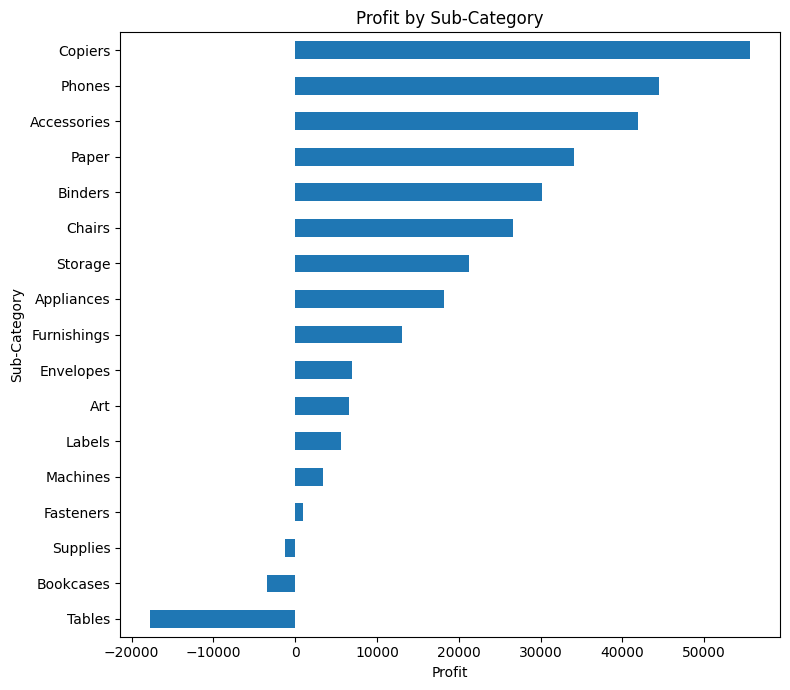

In [9]:
plot_df=subcat.sort_values('Profit')
ax=plot_df.plot(kind='barh', x='Sub-Category', y='Profit', legend=False, figsize=(8,7), title='Profit by Sub-Category')
ax.set_xlabel('Profit')
plt.tight_layout()
plt.show()

## Discount vs Profit

In [10]:
discount = orders.groupby('Discount', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Rows=('Row ID','count'))
discount['Margin %']=discount['Profit']/discount['Sales']*100
discount.sort_values('Discount').round(2)

,Discount,Sales,Profit,Rows,Margin %
0,0.00,1087908.47,320987.60,4798,29.51
1,0.10,54369.35,9029.18,94,16.61
2,0.15,27558.52,1418.99,52,5.15
3,0.20,764594.37,90337.31,3657,11.82
4,0.30,103226.66,-10369.28,227,-10.05
5,0.32,14493.46,-2391.14,27,-16.50
6,0.40,116417.78,-23057.05,206,-19.81
7,0.45,5484.97,-2493.11,11,-45.45
8,0.50,58918.54,-20506.43,66,-34.80
9,0.60,6644.70,-5944.66,138,-89.46


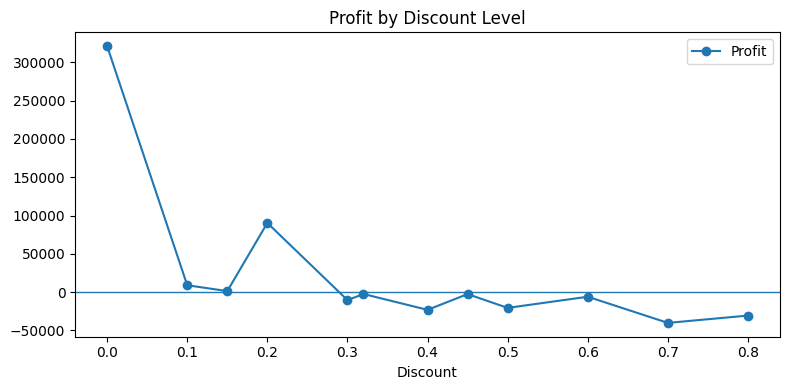

In [11]:
ax=discount.sort_values('Discount').plot(kind='line', x='Discount', y='Profit', marker='o', figsize=(8,4), title='Profit by Discount Level')
ax.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

## Return Rate

In [12]:
returned_orders=set(returns.loc[returns['Returned'].eq('Yes'),'Order ID'])
order_ids=set(orders['Order ID'])
return_rate=len(returned_orders & order_ids)/len(order_ids)*100
pd.Series({'Returned Orders':len(returned_orders & order_ids), 'Total Orders':len(order_ids), 'Return Rate %':return_rate}).round(2)

Returned Orders     296.00
Total Orders       5009.00
Return Rate %         5.91
dtype: float64

In [13]:
orders['Returned'] = orders['Order ID'].isin(returned_orders)
return_by_region = orders.groupby('Region').agg(Total_Orders=('Order ID','nunique'), Returned_Orders=('Returned','sum'))
return_by_region['Return Rate %']=return_by_region['Returned_Orders']/return_by_region['Total_Orders']*100
return_by_region.sort_values('Return Rate %', ascending=False).round(2)

,Total_Orders,Returned_Orders,Return Rate %
Region,,,
West,1611,490,30.42
East,1401,149,10.64
South,822,69,8.39
Central,1175,92,7.83


## Monthly Trend

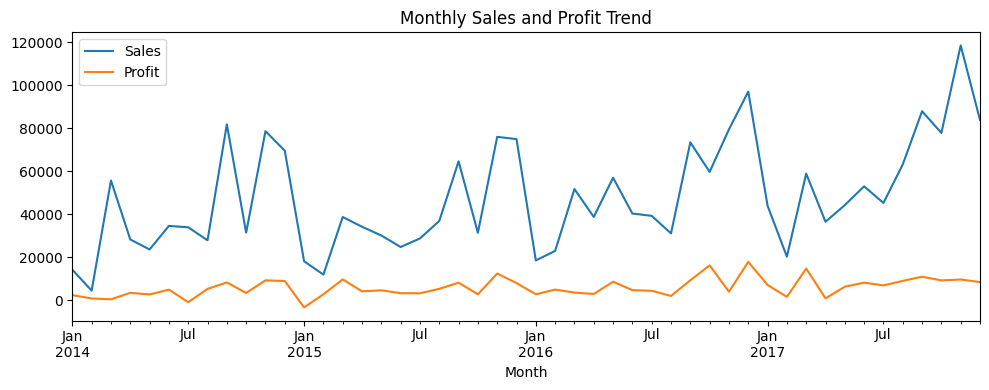

In [14]:
monthly_py=orders.assign(Month=orders['Order Date'].dt.to_period('M').dt.to_timestamp()).groupby('Month', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
ax=monthly_py.plot(x='Month', y=['Sales','Profit'], figsize=(10,4), title='Monthly Sales and Profit Trend')
plt.tight_layout()
plt.show()

## Top & Bottom Products

In [15]:
product=orders.groupby(['Product ID','Product Name'], as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
print('Top 10 products by profit')
display(product.sort_values('Profit', ascending=False).head(10).round(2))
print('Bottom 10 products by profit')
display(product.sort_values('Profit').head(10).round(2))

Top 10 products by profit


,Product ID,Product Name,Sales,Profit
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38,7753.04
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,11619.83,4570.93
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,18374.90,4094.98
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,9367.29,3696.28
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,15875.92,3345.28
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,6965.70,3343.54


Bottom 10 products by profit


,Product ID,Product Name,Sales,Profit
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.64,-2876.12
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,9544.72,-1934.40
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,16656.20,-1299.18
346,FUR-TA-10001950,Balt Solid Wood Round Tables,6518.75,-1201.06
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,1706.25,-1148.44


## Executive Takeaways

1. West is the strongest region by revenue and profit.
2. Technology leads category profitability; Furniture has a materially lower margin.
3. Tables and Bookcases require attention because they are loss-making.
4. High discounts are a profitability risk, with the deepest discount buckets producing substantial losses.
5. The order-level return rate is about 5.9%, which can be monitored by region/category in the dashboard.